# Load Dataset & Library

In [397]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [398]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [399]:
df = pd.read_excel ("/content/drive/MyDrive/Bank_Personal_Loan_Modelling.xlsx", "Data")

# EDA

In [400]:
df.head()

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


In [401]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  5000 non-null   int64  
 1   Age                 5000 non-null   int64  
 2   Experience          5000 non-null   int64  
 3   Income              5000 non-null   int64  
 4   ZIP Code            5000 non-null   int64  
 5   Family              5000 non-null   int64  
 6   CCAvg               5000 non-null   float64
 7   Education           5000 non-null   int64  
 8   Mortgage            5000 non-null   int64  
 9   Personal Loan       5000 non-null   int64  
 10  Securities Account  5000 non-null   int64  
 11  CD Account          5000 non-null   int64  
 12  Online              5000 non-null   int64  
 13  CreditCard          5000 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 547.0 KB


In [402]:
df.columns = df.columns.str.lower()

In [403]:
df.shape

(5000, 14)

In [404]:
df.isnull().sum()

,0
id,0
age,0
experience,0
income,0
zip code,0
family,0
ccavg,0
education,0
mortgage,0
personal loan,0


In [405]:
step = len(df) // 1000
df = df.iloc[::step]
print(df.shape)


(1000, 14)


In [406]:
df.head()

,id,age,experience,income,zip code,family,ccavg,education,mortgage,personal loan,securities account,cd account,online,creditcard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
5,6,37,13,29,92121,4,0.4,2,155,0,0,0,1,0
10,11,65,39,105,94710,4,2.4,3,0,0,0,0,0,0
15,16,60,30,22,95054,1,1.5,3,0,0,0,0,1,1
20,21,56,31,25,94015,4,0.9,2,111,0,0,0,1,0


In [407]:
df = df.drop(columns=['id','zip code'], errors='ignore')
print(df.columns)

Index(['age', 'experience', 'income', 'family', 'ccavg', 'education',
       'mortgage', 'personal loan', 'securities account', 'cd account',
       'online', 'creditcard'],
      dtype='object')


In [408]:
df.describe()

,age,experience,income,family,ccavg,education,mortgage,personal loan,securities account,cd account,online,creditcard
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000
mean,45.521000,20.276000,72.625000,2.388000,1.917800,1.879000,57.088000,0.081000,0.104000,0.052000,0.599000,0.29400
std,11.724292,11.747588,45.019831,1.144887,1.689099,0.842062,99.115307,0.272972,0.305413,0.222138,0.490346,0.45582
min,23.000000,-3.000000,8.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,35.000000,10.000000,38.000000,1.000000,0.700000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,46.000000,20.000000,63.000000,2.000000,1.500000,2.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.00000
75%,56.000000,30.000000,98.250000,3.000000,2.500000,3.000000,101.000000,0.000000,0.000000,0.000000,1.000000,1.00000
max,67.000000,43.000000,204.000000,4.000000,8.800000,3.000000,581.000000,1.000000,1.000000,1.000000,1.000000,1.00000


<Figure size 1200x600 with 0 Axes>

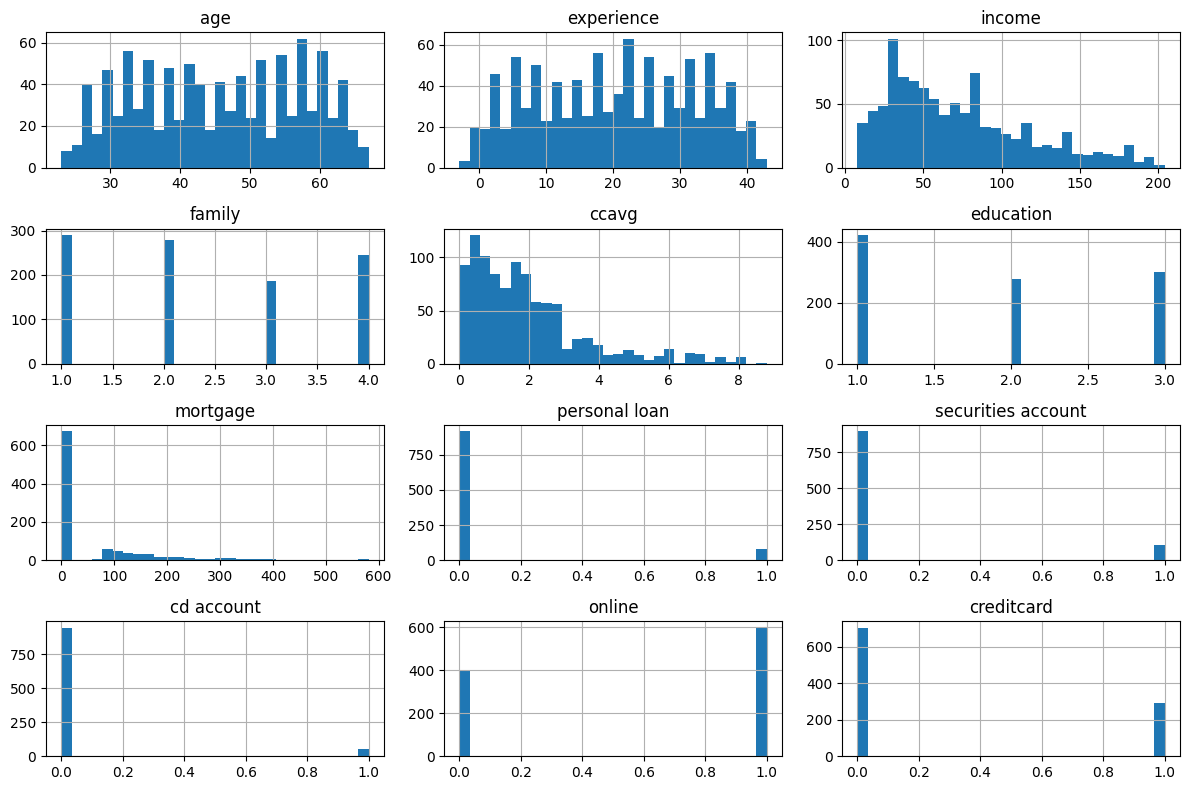

In [409]:
# Distribusi fitur numerik
plt.figure(figsize=(12, 6))
numeric_columns = df.select_dtypes(include=['number']).columns
num_features = len(numeric_columns)
layout_rows = num_features // 3 + (num_features % 3 > 0)
df[numeric_columns].hist(bins=30, figsize=(12, 8), layout=(layout_rows, 3))
plt.tight_layout()
plt.show()

# Heatmap Correlation

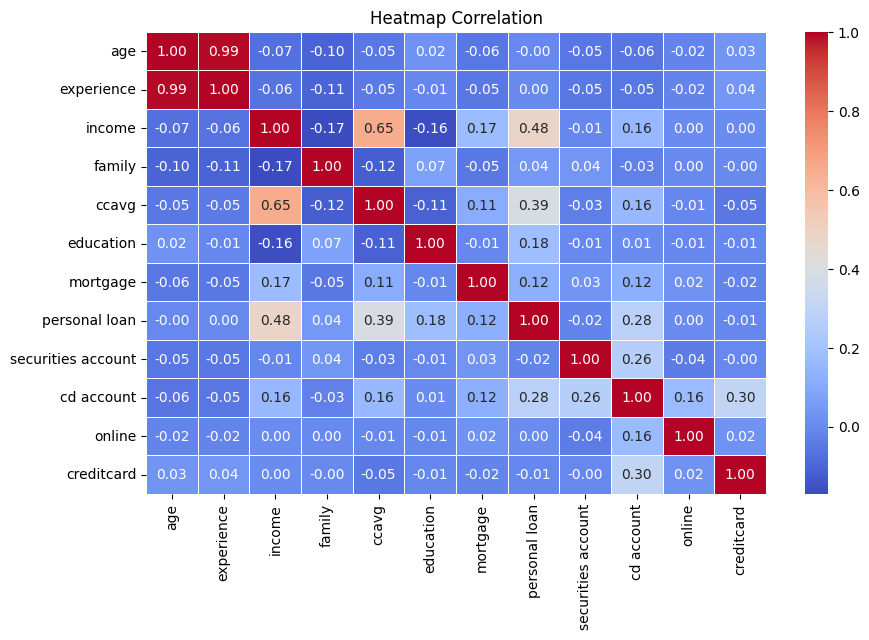

In [410]:
corr_matrix = df.corr()

# Plot heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Heatmap Correlation")
plt.show()

# DATA CLEANING

## Log Transformation

In [411]:
from scipy.stats import skew

# Hitung skewness untuk kolom income dan ccavg
skew_income = skew(df['income'], nan_policy='omit')
skew_ccavg = skew(df['ccavg'], nan_policy='omit')

# Tampilkan hasil
print(f"Skewness Income: {skew_income:.4f}")
print(f"Skewness CCAvg: {skew_ccavg:.4f}")


Skewness Income: 0.8217
Skewness CCAvg: 1.4960


In [412]:
log_cols = df[['ccavg', 'income']]

for c in log_cols:
    df[c] = np.log1p(df[c])

In [413]:
from scipy.stats import skew

# Hitung skewness untuk kolom income dan ccavg
skew_income = skew(df['income'], nan_policy='omit')
skew_ccavg = skew(df['ccavg'], nan_policy='omit')

# Tampilkan hasil
print(f"Skewness Income: {skew_income:.4f}")
print(f"Skewness CCAvg: {skew_ccavg:.4f}")


Skewness Income: -0.3795
Skewness CCAvg: 0.2956


## Outliers Checking & Handling

In [414]:
import pandas as pd

iqr_columns = ['income', 'ccavg', 'mortgage']
outliers_count = {}
outlier_indices = set()  # Simpan indeks outliers

total_rows = len(df)  # Total jumlah baris dalam dataset

for col in iqr_columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    # Hitung jumlah outliers
    outliers_count[col] = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()

    # Simpan indeks baris yang memiliki outliers
    outlier_indices.update(df[(df[col] < lower_bound) | (df[col] > upper_bound)].index)

# Buat DataFrame jumlah outliers per fitur
outliers_df = pd.DataFrame(list(outliers_count.items()), columns=['Feature', 'Outliers Count'])

# Hitung persentase outliers
outliers_df['Percentage (%)'] = (outliers_df['Outliers Count'] / total_rows) * 100

# Tampilkan jumlah dan persentase outliers per fitur
print("Jumlah dan Persentase Outliers per Fitur:")
print(outliers_df)

# Tampilkan baris-baris yang mengandung outliers
df_outliers = df.loc[list(outlier_indices)]
print(f"\nTotal Outliers di Dataset: {len(df_outliers)} ({(len(df_outliers) / total_rows) * 100:.2f}%)")
print("\nBaris yang Mengandung Outliers:")
df_outliers


Jumlah dan Persentase Outliers per Fitur:
    Feature  Outliers Count  Percentage (%)
0    income               5             0.5
1     ccavg               0             0.0
2  mortgage              58             5.8

Total Outliers di Dataset: 63 (6.30%)

Baris yang Mengandung Outliers:


,age,experience,income,family,ccavg,education,mortgage,personal loan,securities account,cd account,online,creditcard
640,43,18,4.454347,1,1.547563,3,327,0,1,0,1,0
1280,65,40,4.595120,3,1.029619,2,333,0,0,0,0,0
130,28,4,4.406719,3,0.916291,1,276,0,0,0,1,0
1665,37,12,4.615121,3,0.788457,3,341,0,0,0,1,1
2820,29,4,4.634729,2,1.458615,1,303,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
1010,27,3,4.595120,2,1.252763,1,361,0,1,1,1,1
1395,47,23,5.252273,4,0.262364,3,305,1,0,0,0,0
1780,49,24,4.418841,1,1.360977,1,267,0,0,0,1,0
3065,39,15,4.804021,1,1.504077,1,368,0,1,0,1,0


In [415]:
for col in iqr_columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    median_value = df[col].median()

    # Ganti outliers dengan median
    df[col] = df[col].apply(lambda x: median_value if x < lower_bound or x > upper_bound else x)

print("Outliers diganti dengan median.")


Outliers diganti dengan median.


## Standarization

In [416]:
df.head()

,age,experience,income,family,ccavg,education,mortgage,personal loan,securities account,cd account,online,creditcard
0,25,1,3.912023,4,0.955511,1,0.0,0,1,0,0,0
5,37,13,3.401197,4,0.336472,2,155.0,0,0,0,1,0
10,65,39,4.663439,4,1.223775,3,0.0,0,0,0,0,0
15,60,30,3.135494,1,0.916291,3,0.0,0,0,0,1,1
20,56,31,3.258097,4,0.641854,2,111.0,0,0,0,1,0


In [417]:
df_copy = df.copy()

In [418]:
from sklearn.preprocessing import StandardScaler

ss = StandardScaler()

df_s = ss.fit_transform(df)

# KMeans

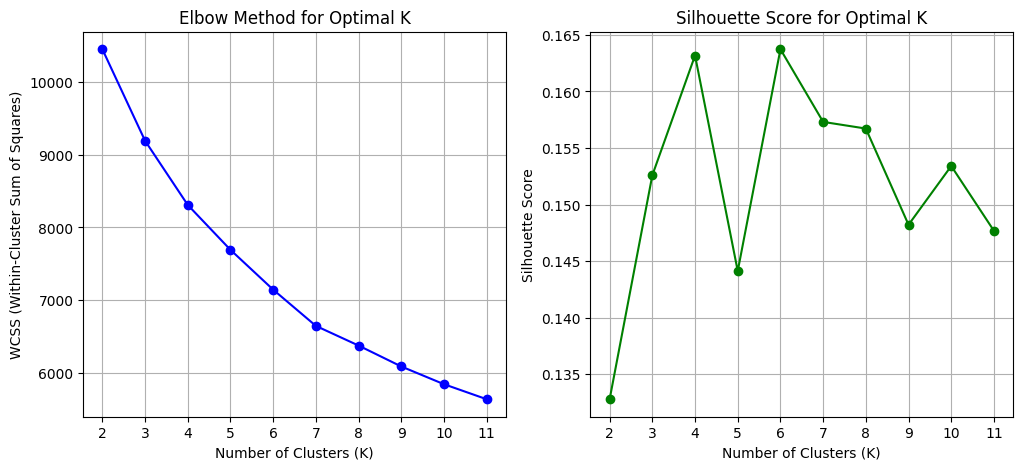

Jumlah klaster optimal berdasarkan Silhouette Score: 6


In [419]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Inisialisasi parameter
wcss = []  # WCSS (Within-Cluster Sum of Squares)
silhouette_scores = []  # Silhouette Scores
K_range = range(2, 12)  # Rentang K dari 2 hingga 11

# Looping untuk mencari K optimal
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(df_s)

    # Simpan nilai WCSS untuk Elbow Method
    wcss.append(kmeans.inertia_)

    # Simpan nilai silhouette score
    silhouette_scores.append(silhouette_score(df_s, labels))

# Menentukan K optimal berdasarkan Silhouette Score (nilai tertinggi)
best_k = K_range[np.argmax(silhouette_scores)]

# Plot Elbow Method & Silhouette Score
plt.figure(figsize=(12, 5))

# Grafik Elbow Method (WCSS vs K)
plt.subplot(1, 2, 1)
plt.plot(K_range, wcss, marker='o', linestyle='-', color='b')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Within-Cluster Sum of Squares)")
plt.title("Elbow Method for Optimal K")
plt.xticks(K_range)
plt.grid(True)

# Grafik Silhouette Score vs K
plt.subplot(1, 2, 2)
plt.plot(K_range, silhouette_scores, marker='o', linestyle='-', color='g')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Optimal K")
plt.xticks(K_range)
plt.grid(True)

# Tampilkan kedua grafik
plt.show()
print(f"Jumlah klaster optimal berdasarkan Silhouette Score: {best_k}")


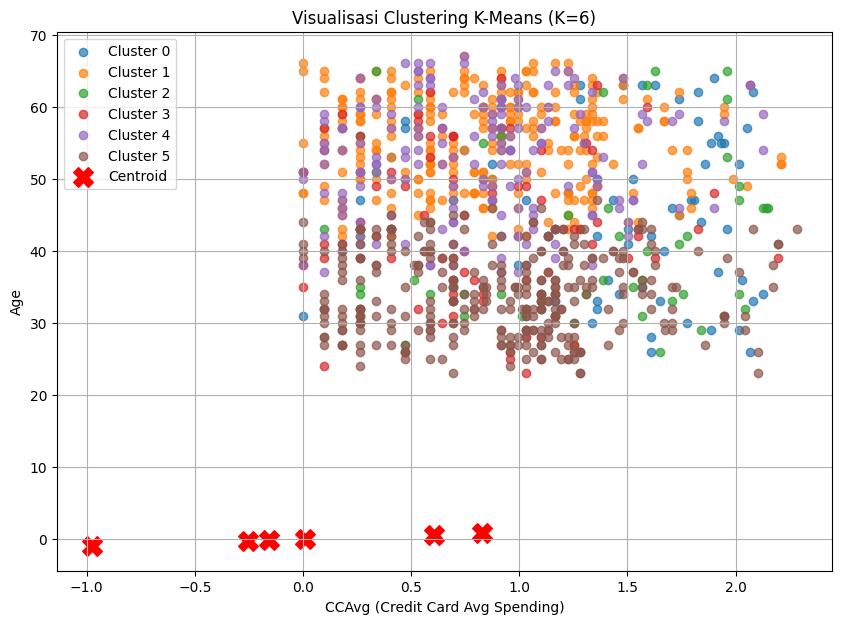

In [420]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans

# Salin DataFrame sebelum menambahkan hasil clustering
df_kmeans = df_copy.copy()


# Jalankan K-Means Clustering
km_model = KMeans(n_clusters=best_k, random_state=42, n_init=10)
labels_optimal = km_model.fit_predict(df_s)  # df_s harus sesuai dengan data yang digunakan untuk clustering

# Tambahkan hasil cluster ke DataFrame asli
df_kmeans["KMeans_label"] = labels_optimal

# Ambil centroid dari hasil K-Means
centroids = km_model.cluster_centers_

# Scatter plot hasil clustering
plt.figure(figsize=(10, 7))
for cluster in range(best_k):
    plt.scatter(
        df_kmeans[df_kmeans["KMeans_label"] == cluster]["ccavg"],
        df_kmeans[df_kmeans["KMeans_label"] == cluster]["age"],
        label=f'Cluster {cluster}',
        alpha=0.7
    )

# Pastikan centroid memiliki dimensi yang sesuai
plt.scatter(
    centroids[:, 0], centroids[:, 1],
    s=200, c='red', marker='X', label='Centroid'
)

# Tambahkan elemen visualisasi
plt.xlabel("CCAvg (Credit Card Avg Spending)")
plt.ylabel("Age")
plt.title(f"Visualisasi Clustering K-Means (K={best_k})")
plt.legend()
plt.grid(True)
plt.show()


In [421]:
df_kmeans.head()

,age,experience,income,family,ccavg,education,mortgage,personal loan,securities account,cd account,online,creditcard,KMeans_label
0,25,1,3.912023,4,0.955511,1,0.0,0,1,0,0,0,3
5,37,13,3.401197,4,0.336472,2,155.0,0,0,0,1,0,5
10,65,39,4.663439,4,1.223775,3,0.0,0,0,0,0,0,1
15,60,30,3.135494,1,0.916291,3,0.0,0,0,0,1,1,4
20,56,31,3.258097,4,0.641854,2,111.0,0,0,0,1,0,1


In [422]:
df_kmeans.groupby('KMeans_label').mean()

,age,experience,income,family,ccavg,education,mortgage,personal loan,securities account,cd account,online,creditcard
KMeans_label,,,,,,,,,,,,
0,45.633333,20.433333,4.939452,2.716667,1.513387,2.433333,28.100000,1.000000,0.066667,0.0,0.500000,0.100000
1,55.202658,29.903654,3.983549,2.086379,0.845758,1.800664,41.873754,0.000000,0.000000,0.0,0.594684,0.000000
2,42.557692,17.538462,4.370573,2.250000,1.229387,1.903846,27.923077,0.403846,0.442308,1.0,0.942308,0.884615
3,43.701299,18.532468,4.096007,2.610390,0.816963,1.844156,31.662338,0.000000,1.000000,0.0,0.467532,0.142857
4,52.601156,27.387283,4.013904,2.300578,0.825356,1.890173,30.294798,0.000000,0.000000,0.0,0.572254,1.000000
5,34.091988,8.818991,4.073803,2.614243,0.928012,1.848665,39.982196,0.000000,0.000000,0.0,0.611276,0.172107


In [423]:
# Menghitung jumlah anggota dalam setiap klaster
df_kmeans['KMeans_label'].value_counts()


,count
KMeans_label,
5,337
1,301
4,173
3,77
0,60
2,52


**Kesimpulan**

* Jumlah Cluster yang Terbentuk: Total ada 6 cluster.

Karakteristik Tiap Cluster:
1. Cluster 0 (Usia Menengah, Pengeluaran Sedang)
  * Rata-rata usia 45 tahun
  * Pengeluaran kartu kredit sekitar 1.5
2. Cluster 1 (Usia Tertua, Pengeluaran Rendah)
  * Rata-rata usia 55 tahun
  * Pengeluaran kartu kredit paling rendah (< 1.0)
3. Cluster 2 (Usia Muda, Pengeluaran Sedang)
  * Rata-rata usia 42 tahun
  * Pengeluaran kartu kredit sekitar 1.2
4. Cluster 3 (Usia Menengah, Pengeluaran Sangat Rendah)
  * Rata-rata usia 43 tahun
  * Pengeluaran kartu kredit paling rendah di bawah 1.0
5. Cluster 4 (Usia Lebih Tua, Pengeluaran Rendah)
  * Rata-rata usia 52 tahun
  * Pengeluaran kartu kredit 0.8 - 0.9
6. Cluster 5 (Usia Muda, Pengeluaran Tinggi)
  * Rata-rata usia 34 tahun
  * Pengeluaran kartu kredit tertinggi (di atas 0.9 - 1.0)

#  Hierarchical Clustering

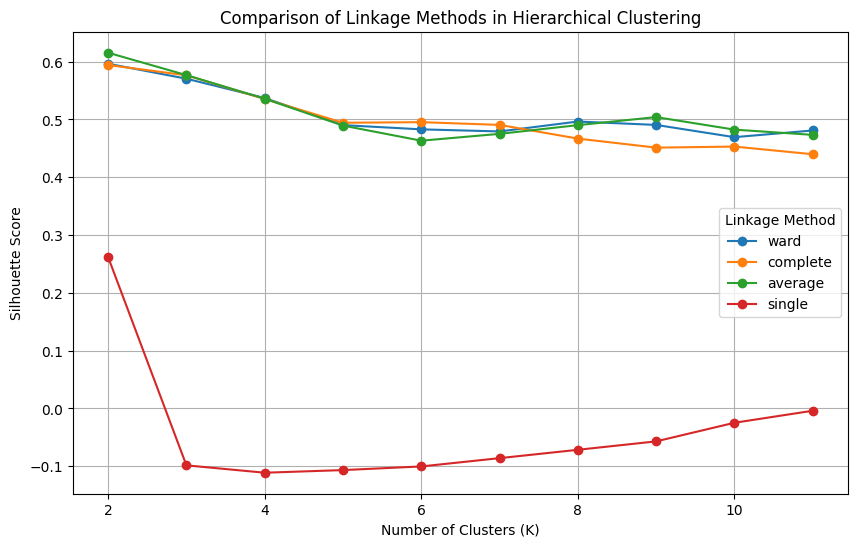

In [424]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

# Asumsikan df_s adalah data yang telah distandardisasi
df_s = df[["ccavg", "age"]].copy()  # Sesuaikan dengan fitur yang digunakan

# Rentang jumlah cluster yang diuji
k_values = range(2, 12)

# Metode linkage yang akan dibandingkan
linkage_methods = ["ward", "complete", "average", "single"]

# Simpan hasil silhouette score untuk setiap metode
silhouette_scores = {method: [] for method in linkage_methods}

for method in linkage_methods:
    for k in k_values:
        model = AgglomerativeClustering(n_clusters=k, linkage=method)
        labels = model.fit_predict(df_s)
        score = silhouette_score(df_s, labels)
        silhouette_scores[method].append(score)

# Plot hasil perbandingan Silhouette Score
plt.figure(figsize=(10, 6))
for method in linkage_methods:
    plt.plot(k_values, silhouette_scores[method], marker="o", linestyle="-", label=method)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Comparison of Linkage Methods in Hierarchical Clustering")
plt.legend(title="Linkage Method")
plt.grid(True)
plt.show()


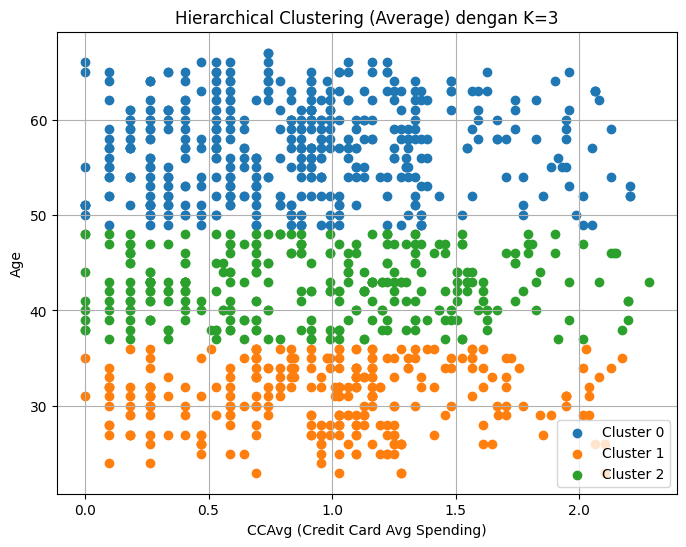

In [425]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage
from sklearn.cluster import AgglomerativeClustering

# Salin dataset asli agar tidak berubah
df_hc = df_copy.copy()

# Lakukan hierarchical clustering menggunakan df_s (yang sudah dinormalisasi)
linkage_matrix = linkage(df_s, method='average')

# Buat model clustering dengan K=2
model = AgglomerativeClustering(n_clusters=3, linkage='average')
labels = model.fit_predict(df_s)

# Tambahkan hasil clustering ke salinan dataset asli
df_hc["Cluster_HC"] = labels

# Visualisasi hasil clustering dengan scatter plot
plt.figure(figsize=(8, 6))
for cluster in np.unique(labels):
    plt.scatter(
        df_s[labels == cluster]["ccavg"],
        df_s[labels == cluster]["age"],
        label=f'Cluster {cluster}'
    )

plt.xlabel("CCAvg (Credit Card Avg Spending)")
plt.ylabel("Age")
plt.title("Hierarchical Clustering (Average) dengan K=3")
plt.legend()
plt.grid(True)
plt.show()


In [426]:
df_hc.head()

,age,experience,income,family,ccavg,education,mortgage,personal loan,securities account,cd account,online,creditcard,Cluster_HC
0,25,1,3.912023,4,0.955511,1,0.0,0,1,0,0,0,1
5,37,13,3.401197,4,0.336472,2,155.0,0,0,0,1,0,2
10,65,39,4.663439,4,1.223775,3,0.0,0,0,0,0,0,0
15,60,30,3.135494,1,0.916291,3,0.0,0,0,0,1,1,0
20,56,31,3.258097,4,0.641854,2,111.0,0,0,0,1,0,0


In [427]:
df_hc.groupby('Cluster_HC').mean()

,age,experience,income,family,ccavg,education,mortgage,personal loan,securities account,cd account,online,creditcard
Cluster_HC,,,,,,,,,,,,
0,57.156542,31.813084,4.038927,2.287383,0.882401,1.894860,38.962617,0.074766,0.084112,0.032710,0.600467,0.313084
1,30.897527,5.625442,4.147697,2.618375,0.983637,1.809187,38.325088,0.091873,0.102473,0.084806,0.646643,0.286219
2,42.608997,17.536332,4.162269,2.311419,0.940139,1.923875,32.432526,0.079585,0.134948,0.048443,0.550173,0.273356


In [428]:
df_hc['Cluster_HC'].value_counts()

,count
Cluster_HC,
0,428
2,289
1,283


**Kesimpulan**

- Terbentuk 3 cluster dengan rentang umur
1. 44 tahun
2. 59 tahun
3. 30 tahun